In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import os
os.environ['JAX_PLATFORM_NAME'] = 'cpu'  # Avoid Metal issues on M1
os.environ['AUTO_DIR'] = '/Users/juannat/Documents/research/auto-07p'  # Required for bifurcation_finder (see docs/INSTALL_AUTO.md)


In [3]:
import numpy as np
import matplotlib.pyplot as plt

import jax
import jax.numpy as jnp
from pprint import pprint

from tipbox import generate


# High-Level API

### 1. Bifurcation-induced

In [4]:
# Generate
full, part, info = generate.generate(
    key=jax.random.PRNGKey(123),
    steps_before_transition=1,
    num_timesteps=500,
    sigma_tilde=0.01,
    tipping_type='transcritical',
    null_simulation=False,
    param_end_multiplier=2.0
)


W0000 00:00:1762973735.762819 23513977 mps_client.cc:510] WARNING: JAX Apple GPU support is experimental and not all JAX functionality is correctly supported!
I0000 00:00:1762973735.796376 23513977 service.cc:145] XLA service 0x131114ab0 initialized for platform METAL (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1762973735.796519 23513977 service.cc:153]   StreamExecutor device (0): Metal, <undefined>
I0000 00:00:1762973735.798596 23513977 mps_client.cc:406] Using Simple allocator.
I0000 00:00:1762973735.798606 23513977 mps_client.cc:384] XLA backend will use up to 5726240768 bytes on device 0 for SimpleAllocator.


Metal device set to: Apple M1

systemMemory: 8.00 GB
maxCacheSize: 2.67 GB

Runner configured
Runner configured
gfortran -g -fopenmp -O -c model.f90 -o model.o
gfortran -g -fopenmp -O model.o -o model.exe /Users/juannat/Documents/research/auto-07p/lib/*.o
Starting model ...

  BR    PT  TY  LAB       a2         L2-NORM          x             y       
   1    47  UZ    2   5.00000E+00   2.71338E+00   2.30430E+00   1.43269E+00

 Total Time    0.519E-02
model ... done
Saving to b.outa2, s.outa2, and d.outa2 ... done
Deleting fort.* *.o *.exe *.*~ ... done
Runner configured
Runner configured
gfortran -g -fopenmp -O -c model.f90 -o model.o
gfortran -g -fopenmp -O model.o -o model.exe /Users/juannat/Documents/research/auto-07p/lib/*.o
Starting model ...

  BR    PT  TY  LAB       a3         L2-NORM          x             y       
   1    58  UZ    2   5.00000E+00   2.56994E+00   2.16373E+00   1.38667E+00

 Total Time    0.252E-02
model ... done
Saving to b.outa3, s.outa3, and d.outa3 ... don

In [5]:
pprint(info)

{'attempt': 2,
 'bifurcation': BifurcationPoint(bif_type='transcritical',
                                 bif_param_name='b5',
                                 bif_param_index=14,
                                 bif_value=4.5087465979),
 'label': 'transcritical',
 'model': PolynomialModel(pars_a=Array([ 0.60716975,  0.51485264, -0.10658372,  0.63440895,  0.        ,
       -0.2989462 , -0.38937247, -0.        , -0.6316599 , -0.        ],      dtype=float32),
                          pars_b=Array([ 0.        ,  0.        , -0.39759177,  0.        , -1.0724171 ,
        0.        , -0.        , -1.7844235 , -0.        , -0.        ],      dtype=float32),
                          s0=Array([-2.133865, -3.617391], dtype=float32),
                          equi=Array([2.4352255, 0.       ], dtype=float32),
                          recovery_rate=3.009169340133667),
 'param_value_transition': 4.443437576293945,
 'steps_before_transition': 1,
 'transition_index': 820}


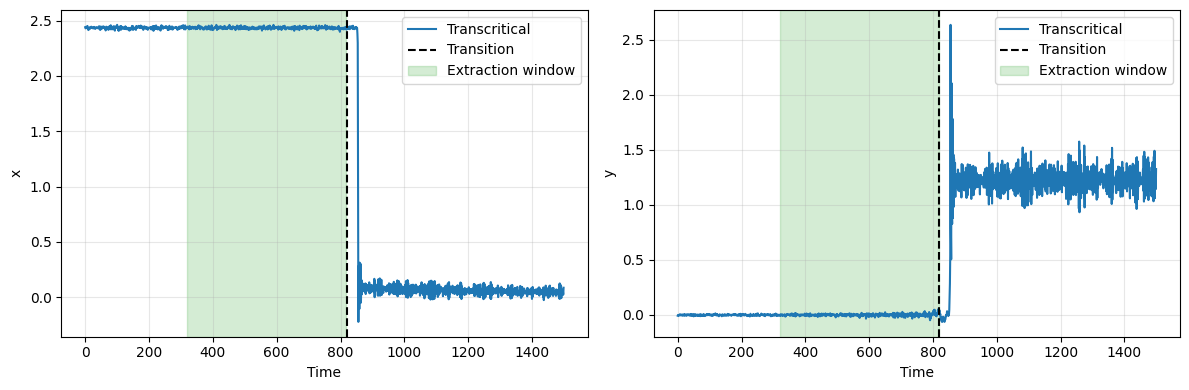

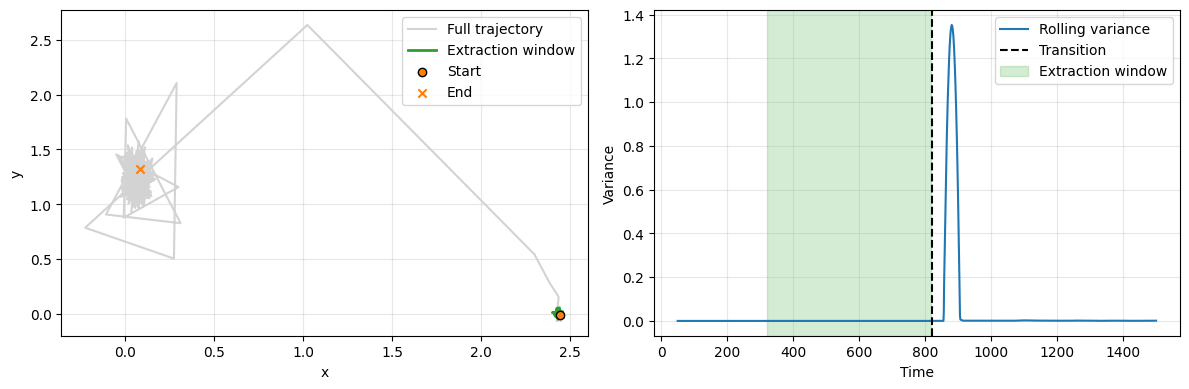

In [6]:
# Visualize the trajectory
full_time = np.asarray(full.time)
full_traj = np.asarray(full.trajectory)
part_traj = np.asarray(part.trajectory)

transition_idx = int(full.metadata.get("transition_index", full_traj.shape[0]))
window_len = part_traj.shape[0]
window_start_idx = max(0, transition_idx - window_len - full.metadata.get("steps_before_transition", 0))
window_end_idx = min(window_start_idx + window_len, full_traj.shape[0])

label = str(full.metadata.get("label", "unknown")).upper()

def extraction_span(ax):
    """Highlight the extraction window on time-series plots."""
    ax.axvspan(full_time[window_start_idx],
               full_time[window_end_idx - 1],
               color="C2", alpha=0.20, label="Extraction window")

# Trajectory
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(full_time, full_traj[:, 0], color="C0", label=f"{full.metadata.get('label', 'unknown').capitalize()}")
axes[0].axvline(transition_idx, linestyle="--", color="black", label="Transition")
extraction_span(axes[0])
axes[0].set_xlabel("Time")
axes[0].set_ylabel("x")
axes[0].grid(True, alpha=0.3)
axes[0].legend(loc="best")

axes[1].plot(full_time, full_traj[:, 1], color="C0", label=f"{full.metadata.get('label', 'unknown').capitalize()}")
axes[1].axvline(transition_idx, linestyle="--", color="black", label="Transition")
extraction_span(axes[1])
axes[1].set_xlabel("Time")
axes[1].set_ylabel("y")
axes[1].grid(True, alpha=0.3)
axes[1].legend(loc="best")

plt.tight_layout()
plt.show()

#  Phase space
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(full_traj[:, 0], full_traj[:, 1], color="lightgray", linewidth=1.5, label="Full trajectory")
axes[0].plot(full_traj[window_start_idx:window_end_idx, 0],
             full_traj[window_start_idx:window_end_idx, 1],
             color="C2", linewidth=2.0, label="Extraction window")

axes[0].scatter(full_traj[0, 0], full_traj[0, 1], marker="o", color="C1", edgecolor="k", label="Start", zorder=5)
axes[0].scatter(full_traj[-1, 0], full_traj[-1, 1], marker="x", color="C1", label="End", zorder=6)

axes[0].set_xlabel("x")
axes[0].set_ylabel("y")
axes[0].grid(True, alpha=0.3)
axes[0].legend(loc="best")

# Rolling variance
window = 50  # number of points for the rolling variance window
rolling_var = [
    np.var(full_traj[max(0, i - window):i, 0])
    for i in range(window, full_traj.shape[0])
]
var_time = full_time[window:window + len(rolling_var)]

axes[1].plot(var_time, rolling_var, color="C0", linewidth=1.5, label="Rolling variance")
axes[1].axvline(transition_idx, linestyle="--", color="black", label="Transition")
extraction_span(axes[1])
axes[1].set_xlabel("Time")
axes[1].set_ylabel("Variance")
axes[1].grid(True, alpha=0.3)
axes[1].legend(loc="best")

plt.tight_layout()
plt.show()

### 2. Rate-induced

In [7]:
import jax
from tipbox import generate

full, part, info = generate.generate(
    key=jax.random.PRNGKey(123),
    steps_before_transition=1,
    num_timesteps=500,
    sigma_tilde=0.01,
    tipping_type='rate',
    null_simulation=False,
)


In [8]:
pprint(info)

{'attempt': 4,
 'label': 'rate',
 'param_value_transition': 2.97554612159729,
 'rate_system': 'saddle_node',
 'steps_before_transition': 1,
 'system_config': {'dt': 0.01,
                   'epsilon': 1.25,
                   'initial_state_max': -1.0,
                   'initial_state_min': -10.0,
                   'lambda_max': 3.0,
                   't_end': 8.0,
                   't_start': -16.0,
                   'tip_threshold': 0.0},
 'transition_index': 1628}


/Users/juannat/opt/anaconda3/envs/tipbox/lib/python3.10/site-packages/numpy/_core/_methods.py:194: RuntimeWarning: overflow encountered in multiply
  x = um.multiply(x, x, out=x)
/Users/juannat/opt/anaconda3/envs/tipbox/lib/python3.10/site-packages/numpy/_core/_methods.py:191: RuntimeWarning: invalid value encountered in subtract
  x = asanyarray(arr - arrmean)


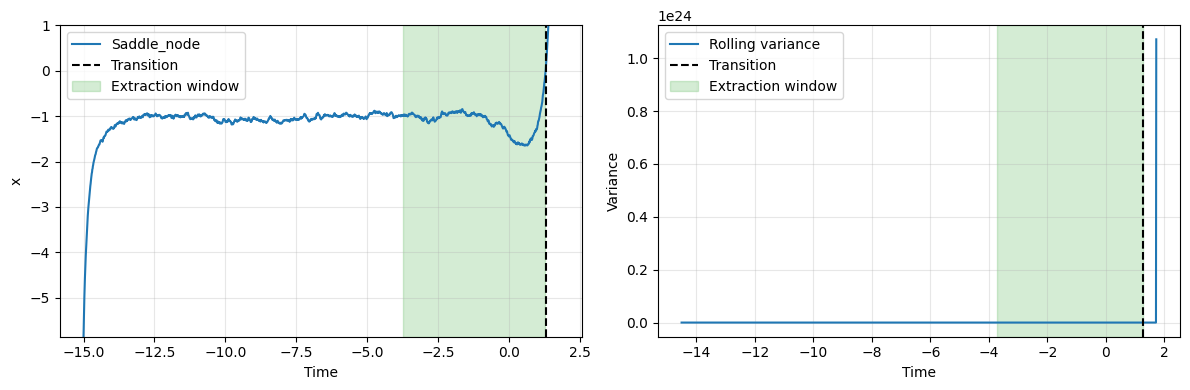

In [9]:
# Visualize the trajectory
full_time = np.asarray(full.time)
full_traj = np.asarray(full.trajectory)
part_traj = np.asarray(part.trajectory)

transition_idx = int(full.metadata.get("transition_index", full_traj.shape[0]))
transition_time = float(full_time[min(transition_idx, full_time.size - 1)])
window_len = part_traj.shape[0]
window_start_idx = max(0, transition_idx - window_len - full.metadata.get("steps_before_transition", 0))
window_end_idx = min(window_start_idx + window_len, full_traj.shape[0])

def add_extraction_span(ax):
    ax.axvspan(
        float(full_time[window_start_idx]), 
        float(full_time[window_end_idx - 1]),
        color="C2", alpha=0.20, label="Extraction window"
    )

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Trajectory
axes[0].plot(full_time, full_traj[:, 0], color="C0", label=f"{full.metadata.get('rate_system', 'unknown').capitalize()}")
axes[0].axvline(transition_time, linestyle="--", color="black", label="Transition")
add_extraction_span(axes[0])
axes[0].set_xlabel("Time")
axes[0].set_ylabel("x")
axes[0].set_ylim(full_traj[0, 0], 1)
axes[0].grid(True, alpha=0.3)
axes[0].legend(loc="best")

# Rolling variance
window = 50
rolling_var = np.array([
    np.var(full_traj[max(0, i - window):i, 0])
    for i in range(window, full_traj.shape[0])
])
var_time = full_time[window:window + len(rolling_var)]

axes[1].plot(var_time, rolling_var, color="C0", linewidth=1.5, label="Rolling variance")
axes[1].axvline(transition_time, linestyle="--", color="black", label="Transition")
add_extraction_span(axes[1])
axes[1].set_xlabel("Time")
axes[1].set_ylabel("Variance")
axes[1].grid(True, alpha=0.3)
axes[1].legend(loc="best")

plt.tight_layout()
plt.show()